Name - Rajat Kumar Majumdar
CU240251642

Roll No:49

Section: B

Experiment No. 9

Experiment Name

Object Detection and Recognition using Deep Learning Models on Standard Image
Datasets

Aim

To implement a deep learning-based object detection and recognition system using pre-trained models and evaluate its performance on standard image datasets for identifying and localizing multiple objects.

Purpose

Object detection is one of the most significant tasks in computer vision, combining object
localization and object classification within an image. Unlike image classification, which
predicts only the image category, object detection identifies the location of one or more objects
by generating bounding boxes along with class labels.
In this experiment, students will utilize pre-trained deep learning models such as YOLOv8,
SSD (Single Shot Detector), or Faster R-CNN to detect and recognize objects from standard
datasets such as MS COCO, Pascal VOC, or Open Images Dataset. The experiment provides
practical exposure to modern object detection frameworks widely used in autonomous vehicles,
surveillance systems, healthcare, and smart city applications.

Prerequisites

• Basic knowledge of Digital Image Processing

• Familiarity with Python programming

• Python libraries: OpenCV (cv2), Ultralytics YOLO, PyTorch/TensorFlow, NumPy,
and

Matplotlib

• Understanding of Convolutional Neural Networks (CNNs)

• Jupyter Notebook, Google Colab, or Visual Studio Code

Steps

1. Install and import the required libraries, including OpenCV and the chosen deep
learning framework (e.g., Ultralytics YOLO or TensorFlow).
2. Load a pre-trained object detection model such as YOLOv8, SSD, or Faster R-CNN.
3. Download or access images from a standard dataset such as MS COCO, Pascal VOC,
or Open Images Dataset.
4. Perform any necessary image preprocessing, including resizing and normalization,
before inference.
5. Apply the object detection model to identify and localize objects within the selected
images.
6. Display the detected objects with bounding boxes, class labels, and confidence scores.
7. Evaluate the detection results by analyzing correctly detected objects, false detections,
and missed objects.
8. Compare the performance of different object detection models in terms of detection
accuracy and inference speed (if multiple models are used).
9. Analyze the suitability of the selected model for real-world applications such as
autonomous driving, surveillance, retail analytics, or industrial inspection.
10. Summarize the observations and discuss the advantages and limitations of deep
learning-based object detection techniques

In [1]:
%pip install -q ultralytics opencv-python matplotlib pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 79.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 11.6 MB/s eta 0:00:00


In [2]:

# Step 2: Import the required libraries

import cv2
import time
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from ultralytics import YOLO
from IPython.display import display

print("All libraries imported successfully!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
All libraries imported successfully!


In [4]:
# Step 3: Load the pre-trained YOLOv8 model

# Load the pre-trained YOLOv8 Nano model
model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully!")
print("Model: YOLOv8 Nano")
print("Dataset classes:", len(model.names))


YOLOv8 model loaded successfully!
Model: YOLOv8 Nano
Dataset classes: 80


In [5]:
# Step 4: Load a standard image dataset


from ultralytics.utils.downloads import download

dataset_url = (
    "https://github.com/ultralytics/assets/releases/"
    "download/v0.0.0/coco128.zip"
)

dataset_dir = Path("datasets/coco128")

if not dataset_dir.exists():
    download(dataset_url, dir="datasets", unzip=True)

image_dir = dataset_dir / "images" / "train2017"

if not image_dir.exists():
    raise FileNotFoundError(
        "Dataset images not found. Check the download or dataset path."
    )

image_paths = sorted(image_dir.glob("*.jpg"))

print("Dataset loaded successfully!")
print("Number of images:", len(image_paths))
print("First image:", image_paths[0] if image_paths else "No images found")

Unzipping datasets/coco128.zip to /content/datasets/coco128...: 100% ━━━━━━━━━━━━ 263/263 3.6Kfiles/s 0.1s
Dataset loaded successfully!
Number of images: 128
First image: datasets/coco128/images/train2017/000000000009.jpg


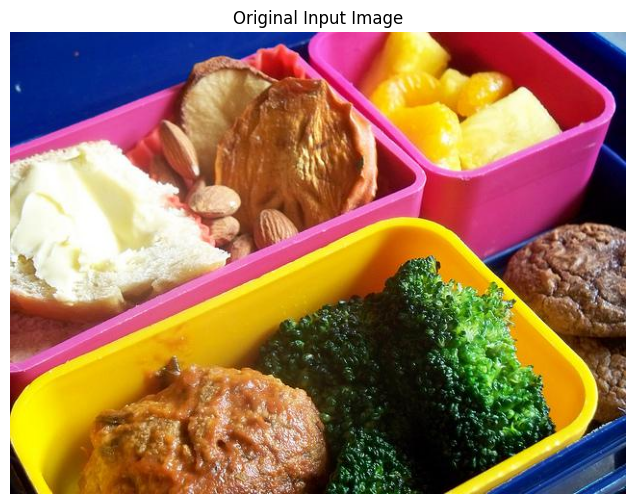

In [6]:
# Step 5: Display a sample input image

# Select the first image
image_path = str(image_paths[0])

# Read image using OpenCV
image = cv2.imread(image_path)

# Convert BGR to RGB for correct visualization
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(image_rgb)
plt.title("Original Input Image")
plt.axis("off")
plt.show()

Original image shape: (480, 640, 3)
Resized image shape: (640, 640, 3)
Normalized pixel range: 0.0 to 1.0


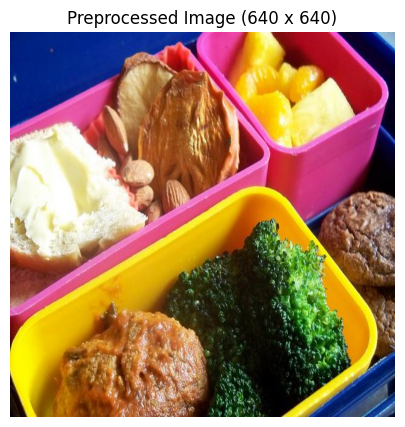

In [7]:
# Step 6: Preprocess the image


# Resize image for visualization and preprocessing demonstration
resized_image = cv2.resize(image_rgb, (640, 640))

# Normalize pixel values to the range 0 to 1
normalized_image = resized_image.astype("float32") / 255.0

print("Original image shape:", image_rgb.shape)
print("Resized image shape:", resized_image.shape)
print("Normalized pixel range:",
      normalized_image.min(), "to", normalized_image.max())

plt.figure(figsize=(6, 5))
plt.imshow(normalized_image)
plt.title("Preprocessed Image (640 x 640)")
plt.axis("off")
plt.show()

In [8]:
# Step 7: Perform object detection


# Run object detection
results = model.predict(
    source=image_path,
    conf=0.25,
    verbose=False
)

result = results[0]

print("Object detection completed successfully!")
print("Image:", image_path)
print("Number of detected objects:", len(result.boxes))

Object detection completed successfully!
Image: datasets/coco128/images/train2017/000000000009.jpg
Number of detected objects: 6


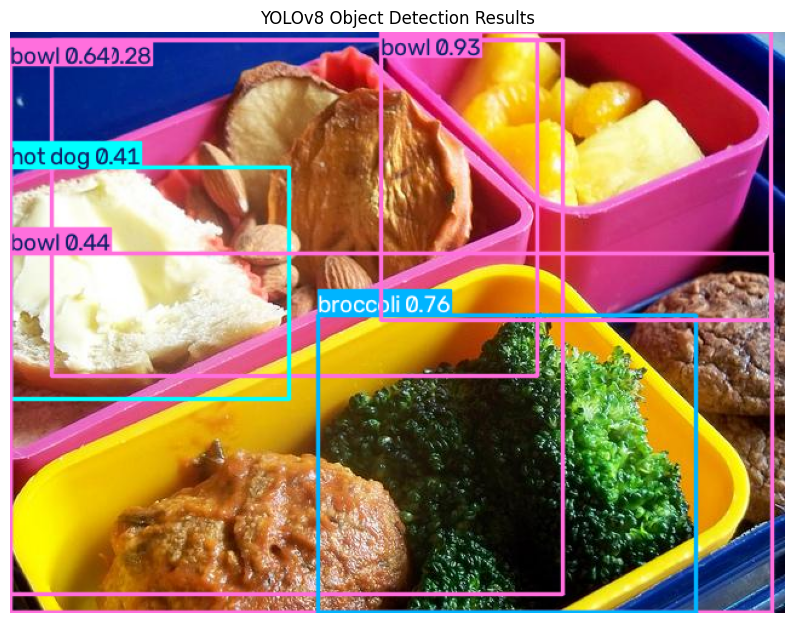

In [9]:
# Step 8: Display bounding boxes,

# Plot the detection result
annotated_image = result.plot()

# YOLO returns the plotted image in BGR format
annotated_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(annotated_rgb)
plt.title("YOLOv8 Object Detection Results")
plt.axis("off")
plt.show()

In [10]:
# Step 9: Display detected objects in tabular form


detections = []

for box in result.boxes:
    class_id = int(box.cls.item())
    confidence = float(box.conf.item())

    x1, y1, x2, y2 = box.xyxy[0].tolist()

    detections.append({
        "Object": model.names[class_id],
        "Confidence": round(confidence, 4),
        "X1": round(x1, 2),
        "Y1": round(y1, 2),
        "X2": round(x2, 2),
        "Y2": round(y2, 2)
    })

detection_df = pd.DataFrame(
    detections,
    columns=["Object", "Confidence", "X1", "Y1", "X2", "Y2"]
)

display(detection_df)

print("Total objects detected:", len(detection_df))

,Object,Confidence,X1,Y1,X2,Y2
0,bowl,0.9276,306.17,0.04,628.67,238.12
1,broccoli,0.7598,254.71,234.24,566.59,479.73
2,bowl,0.6417,0.00,7.75,456.39,464.02
3,bowl,0.4386,0.81,183.75,629.97,479.33
4,hot dog,0.4148,0.33,112.99,230.32,303.61
5,bowl,0.2769,34.83,7.10,435.31,284.30


Total objects detected: 6


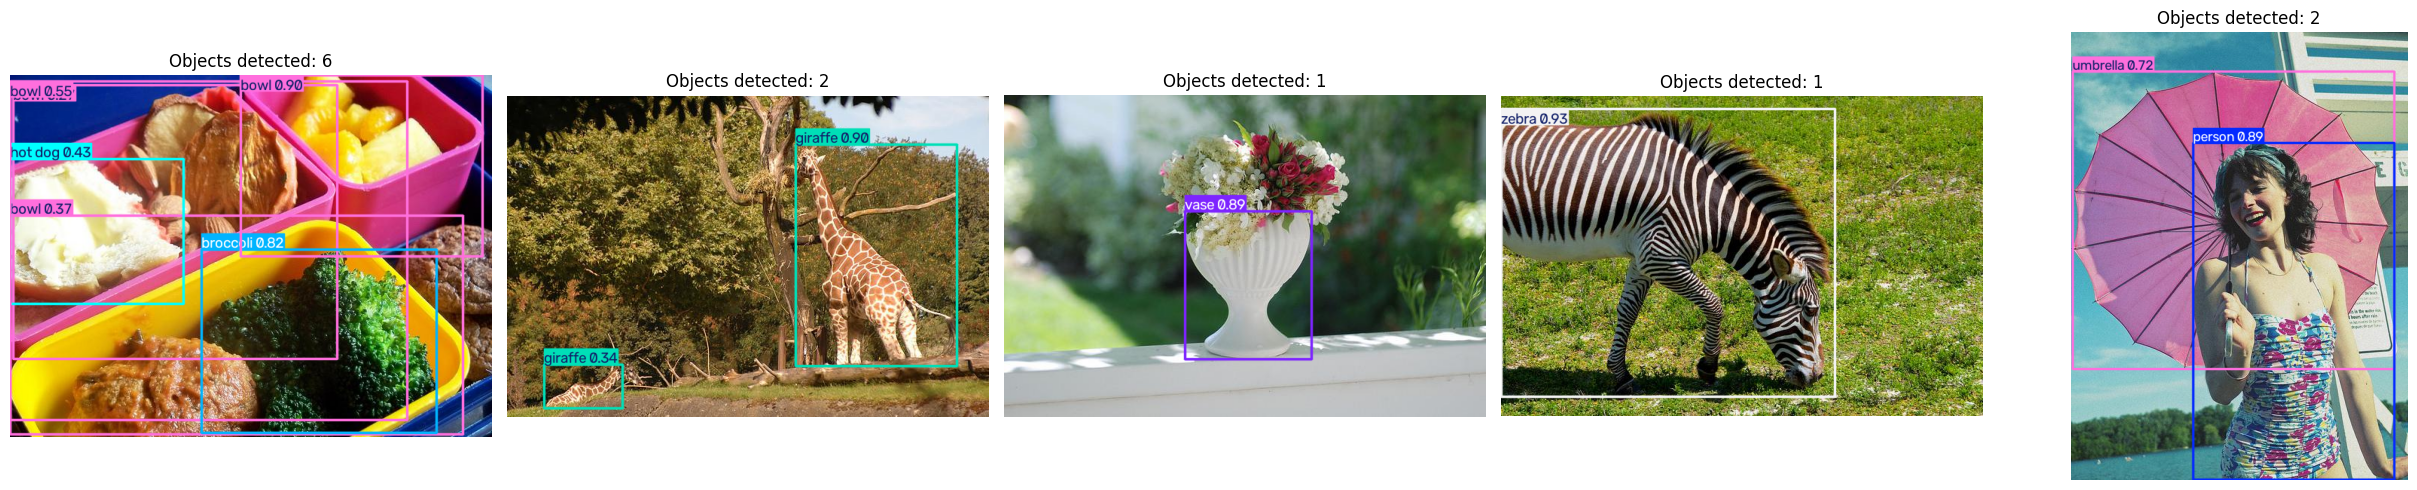

In [12]:
# Step 10: Detect objects in multiple images

# Select up to five images
sample_images = image_paths[:5]

multi_image_results = model.predict(
    source=[str(path) for path in sample_images],
    conf=0.25,
    verbose=False
)

fig, axes = plt.subplots(
    1, len(multi_image_results),
    figsize=(5 * len(multi_image_results), 5)
)

if len(multi_image_results) == 1:
    axes = [axes]

for ax, res in zip(axes, multi_image_results):
    plotted = res.plot()
    plotted = cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB)

    ax.imshow(plotted)
    ax.set_title(f"Objects detected: {len(res.boxes)}")
    ax.axis("off")

plt.tight_layout()
plt.show()


# Experiment No. 9 — Theory Questions and Answers

## Q1. Differentiate between image classification, object detection, and image segmentation.

Answer:

| Feature | Image Classification | Object Detection | Image Segmentation |
| --- | --- | --- | --- |
| Purpose | Identifies the category of an image | Identifies and locates objects | Identifies objects at the pixel level |
| Output | Class label | Class labels and bounding boxes | Pixel-level masks |
| Localization | Not provided | Rectangular bounding boxes | Exact object regions |
| Example | Identifies an image as a dog | Detects a dog with a bounding box | Highlights every pixel belonging to the dog |
| Applications | Image categorization | Surveillance and autonomous driving | Medical imaging and scene analysis |

Image classification identifies what is present in an image, object detection identifies what is present and where it is located, and image segmentation identifies the precise pixels belonging to objects.

## Q2. Explain the working principle of the YOLO (You Only Look Once) object detection algorithm.

Answer:

YOLO is a single-stage object detection algorithm that detects and classifies objects in an image in a single forward pass through a neural network.

The working steps are:

1. Input image: The image is provided to the model.
2. Preprocessing: The image is resized and prepared for processing.
3. Feature extraction: A convolutional neural network extracts important image features.
4. Object prediction: The model predicts bounding boxes, class labels, and confidence scores.
5. Confidence filtering: Low-confidence detections are removed.
6. Non-Maximum Suppression (NMS): Duplicate overlapping detections are filtered.
7. Output: The final detected objects are displayed with bounding boxes, labels, and confidence scores.

Advantages: YOLO offers high speed, efficient processing, and suitability for real-time object detection.

Applications: Autonomous vehicles, surveillance, robotics, and traffic monitoring.

## Q3. Compare YOLO, SSD, and Faster R-CNN based on speed, accuracy, and practical applications.

Answer:

| Feature | YOLO | SSD | Faster R-CNN |
| --- | --- | --- | --- |
| Full form | You Only Look Once | Single Shot Detector | Faster Region-based Convolutional Neural Network |
| Architecture | Single-stage | Single-stage | Two-stage |
| Speed | Generally very fast | Generally fast | Generally slower |
| Accuracy | High, depending on model | Good, depending on configuration | Often strong localization accuracy |
| Computation | Varies by model size | Generally moderate | Often higher |
| Applications | Real-time detection and robotics | Embedded systems and real-time detection | Detailed object detection and research |

YOLO is commonly preferred for real-time applications because of its speed. SSD provides another efficient single-stage approach, while Faster R-CNN uses region proposals and a second stage for object classification and bounding-box refinement.

Actual performance depends on the model configuration, dataset, and hardware.

## Q4. What is a bounding box? Why is it important in object detection?

Answer:

A bounding box is a rectangular box drawn around an object in an image to indicate its location.

It is commonly represented by four coordinates:

$$
(x_{\min}, y_{\min}, x_{\max}, y_{\max})
$$

Here, $x_{\min}, y_{\min}$ represent the top-left corner, and $x_{\max}, y_{\max}$ represent the bottom-right corner.

Importance of bounding boxes:

1. They indicate the location of detected objects.
2. They help distinguish objects from the background.
3. They support object counting and tracking.
4. They help measure localization accuracy using IoU.
5. They are useful in applications such as vehicle detection, surveillance, and industrial inspection.

## Q5. Explain the significance of confidence score and Intersection over Union (IoU) in object detection.

Answer:

Confidence score: It represents the model's confidence in a predicted detection and its associated class. A higher score generally indicates stronger confidence in the prediction, but it does not guarantee correctness.

A confidence threshold is used to remove predictions below a selected score.

Intersection over Union (IoU): IoU measures the overlap between a predicted bounding box and the ground-truth bounding box.

$$
IoU=\frac{\text{Area of Intersection}}{\text{Area of Union}}
$$

IoU ranges from 0 to 1:

- IoU = 0: No overlap.
- IoU = 1: Perfect overlap.

Significance:

- Confidence scores help filter unreliable predictions.
- IoU measures the accuracy of object localization.
- IoU is used in model evaluation and duplicate-box suppression.
- Both help analyze the quality of object detection results.

## Q6. What are the advantages of using pre-trained deep learning models over traditional image processing techniques?

Answer:

Pre-trained deep learning models offer the following advantages:

1. High accuracy: They can recognize complex objects and patterns.
2. Reduced training time: Existing model weights eliminate the need to train from scratch.
3. Automatic feature extraction: They learn useful features directly from training images.
4. Multiple object detection: They can identify several objects in one image.
5. Robustness: They can handle variations in lighting, shape, and viewpoint, depending on training.
6. Transfer learning: They can be fine-tuned for specific applications.
7. Scalability: They can be adapted to different applications and hardware platforms.

Traditional image-processing methods can still be useful for simple, controlled environments but often require manually designed features and rules.

## Q7. Why are datasets such as MS COCO and Pascal VOC widely used for object detection research?

Answer:

MS COCO and Pascal VOC are widely used because they provide labeled images and standard benchmarks for training and evaluating object detection models.

MS COCO (Microsoft Common Objects in Context):

- Contains diverse images of everyday scenes.
- Provides annotations for object classes and bounding boxes.
- Includes objects of different sizes, often with occlusion and complex backgrounds.
- Supports evaluation using metrics such as mean Average Precision (mAP).

Pascal VOC (Visual Object Classes):

- Provides annotated images belonging to standard object categories.
- Includes object classification and bounding-box annotations.
- Supports standardized evaluation and model comparison.
- Is widely used in research and educational experiments.

These datasets help researchers train models, evaluate their performance, and compare different detection algorithms using consistent evaluation protocols.

## Q8. Mention five real-world applications of object detection in computer vision.

Answer:

1. Autonomous driving: Detects vehicles, pedestrians, traffic signs, and road obstacles.
2. Surveillance and security: Detects people, vehicles, and objects in video footage.
3. Healthcare: Helps identify relevant structures or suspicious regions in medical images when appropriately validated.
4. Retail analytics: Detects products, monitors shelf inventory, and supports store analytics.
5. Industrial inspection: Identifies defective products, missing components, and manufacturing faults.

Other applications include agriculture, robotics, traffic management, sports analytics, and wildlife monitoring.

## Q9. What challenges are commonly encountered while detecting objects in complex real-world environments?

Answer:

Common challenges include:

1. Occlusion: Objects may be partially hidden by other objects.
2. Lighting variations: Shadows, glare, and poor illumination affect detection.
3. Scale variation: Objects may appear at different sizes and distances.
4. Complex backgrounds: Background elements may resemble target objects.
5. Overlapping objects: Closely positioned objects may be difficult to separate.
6. Motion blur: Fast-moving objects may appear unclear.
7. Insufficient training data: Limited or poorly labeled images can reduce accuracy.
8. Class imbalance: Some categories may have fewer training examples than others.
9. Computational limitations: Complex models may require substantial memory and processing power.
10. False detections: Models may incorrectly detect objects or miss real objects.

These challenges can be reduced through better training data, data augmentation, improved model architectures, and careful evaluation.

## Q10. How can object detection systems be further improved using recent advancements in deep learning and computer vision?

Answer:

Object detection systems can be improved through the following techniques:

1. Advanced architectures: Use improved YOLO models, transformer-based detectors, and other modern architectures.
2. Transfer learning: Fine-tune pre-trained models using application-specific datasets.
3. Data augmentation: Use image flipping, cropping, scaling, and color transformations to improve robustness.
4. Small-object detection: Use higher-resolution inputs and multi-scale feature extraction.
5. Attention mechanisms: Help models focus on important image regions.
6. Model optimization: Apply quantization, pruning, and knowledge distillation to reduce computational requirements.
7. Hardware acceleration: Use GPUs and optimized inference frameworks.
8. Improved datasets: Collect diverse images and correct annotation errors.
9. Object tracking: Combine detection across video frames for more consistent results.
10. Real-world evaluation: Test precision, recall, mAP, and inference speed under different conditions.

These improvements can increase accuracy, speed, robustness, and suitability for practical applications.

## Result

The object detection experiment was performed using the pre-trained YOLOv8 model and the COCO128 image dataset. Multiple objects were detected and localized using bounding boxes, class labels, and confidence scores. The experiment demonstrated the use of deep learning for object recognition and evaluation.

## Conclusion

The experiment demonstrated that deep learning-based object detection can identify and localize multiple objects in images. YOLOv8 provides an efficient approach for real-time detection, while evaluation metrics such as precision, recall, and mAP help measure performance. Object detection is useful in autonomous driving, surveillance, healthcare, retail analytics, and industrial inspection.